In [2]:

import numpy as np # linear algebra
import struct
from array import array
from os.path  import join

#
# MNIST Data Loader Class
#
class MnistDataloader(object):
    def __init__(self, training_images_filepath,training_labels_filepath,
                 test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath
    
    def read_images_labels(self, images_filepath, labels_filepath):        
        labels = []
        with open(labels_filepath, 'rb') as file:
            magic, size = struct.unpack(">II", file.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array("B", file.read())        
        
        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic))
            image_data = array("B", file.read())        
        images = []
        for i in range(size):
            images.append([0] * rows * cols)
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images[i][:] = img            
        
        return images, labels
            
    def load_data(self):
        x_train, y_train = self.read_images_labels(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images_labels(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train),(x_test, y_test)    



In [3]:
cd

C:\Users\Als


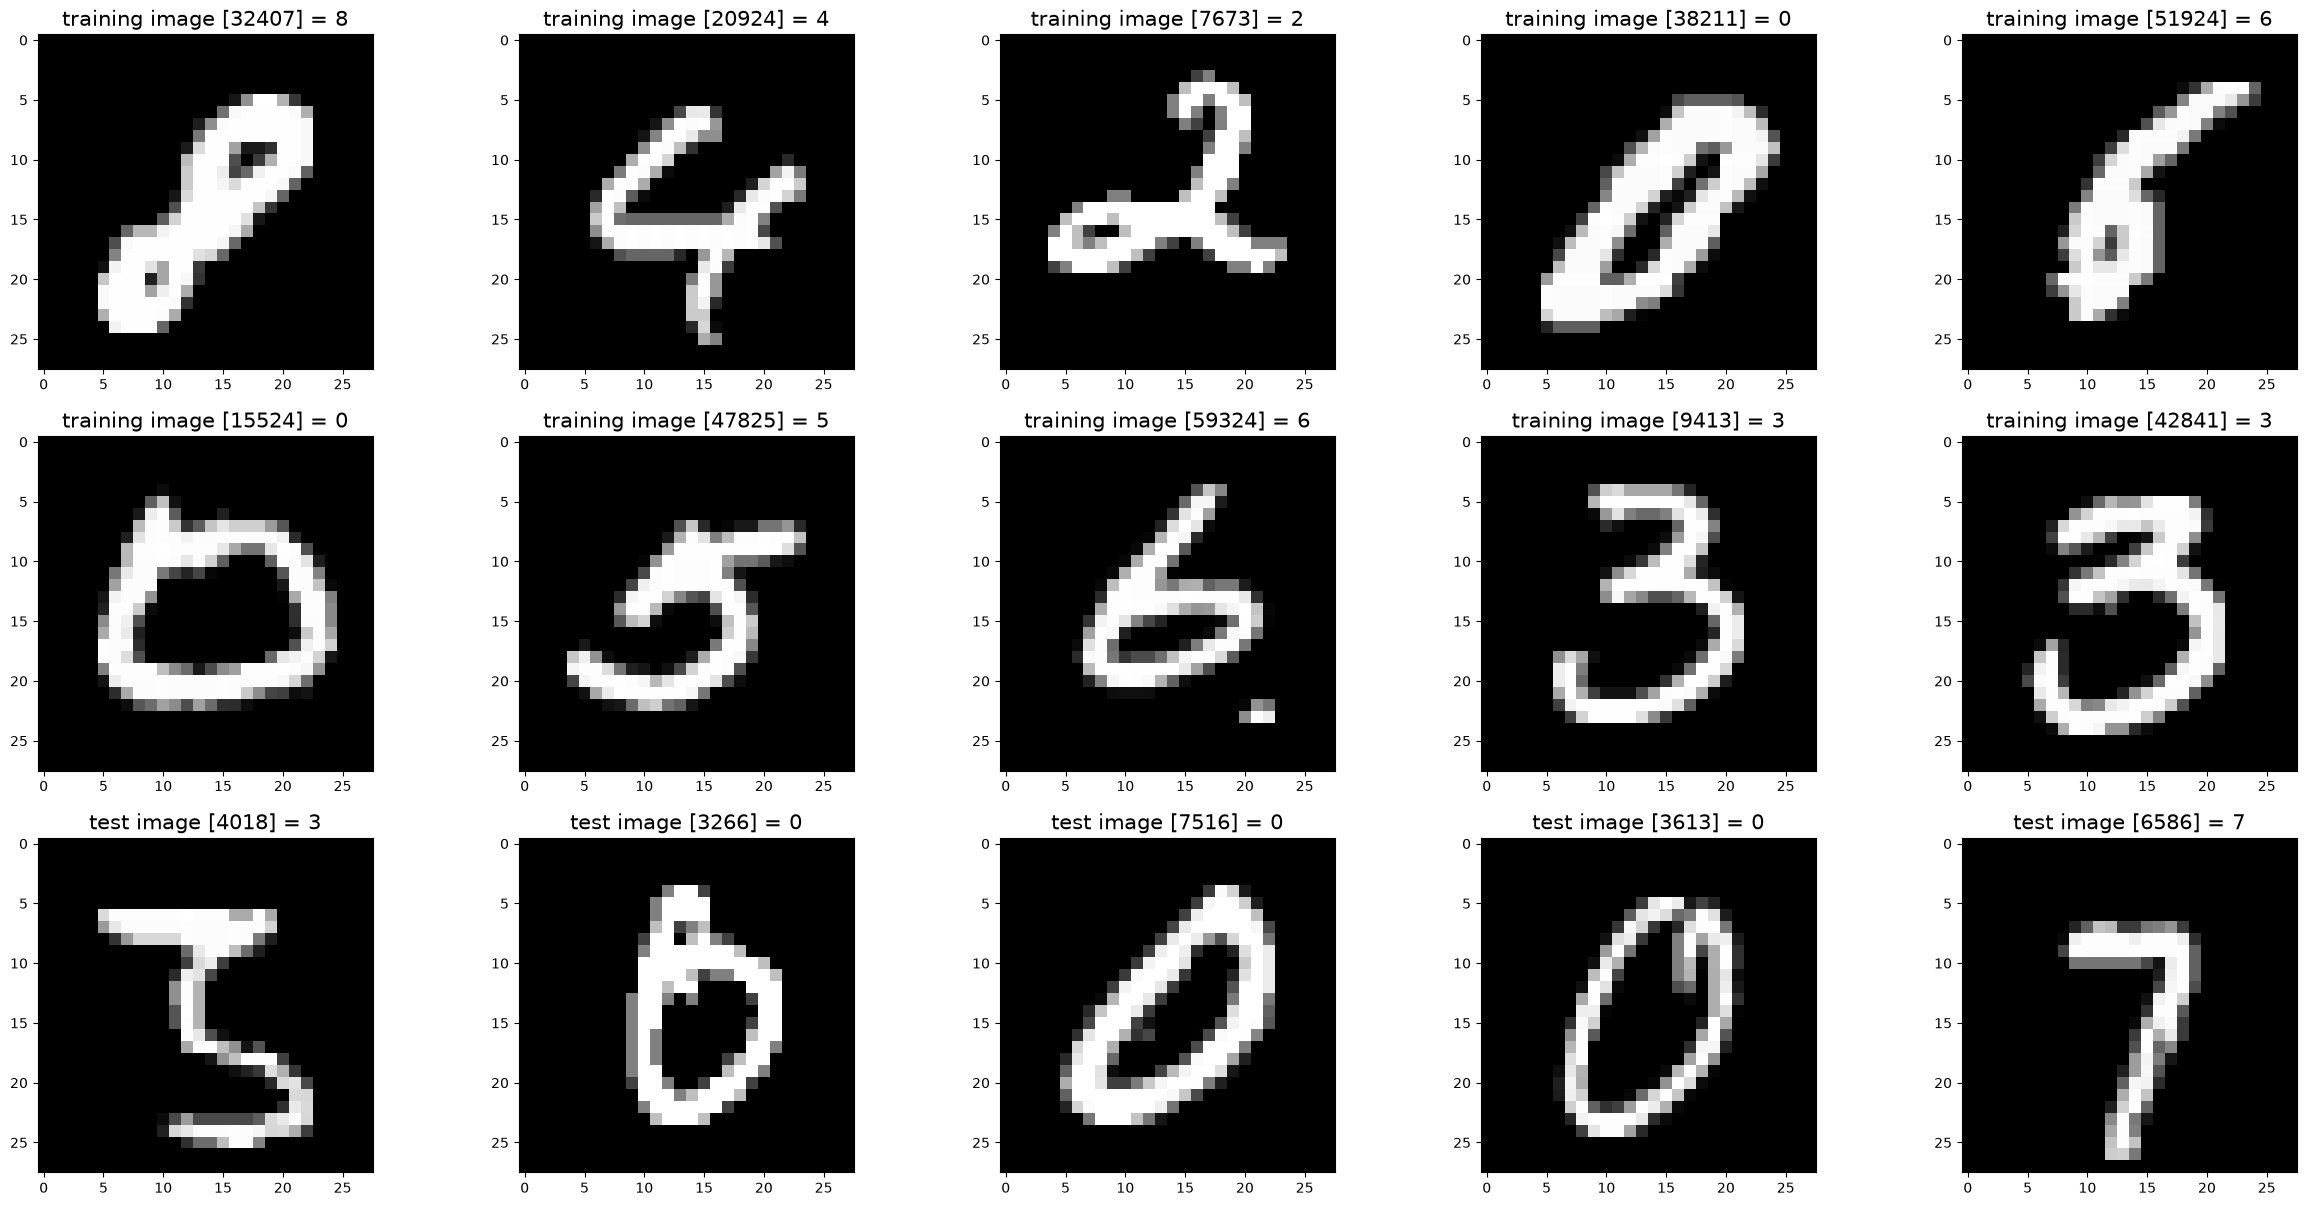

In [4]:
%matplotlib inline
import random
import matplotlib.pyplot as plt

#
# Set file paths based on added MNIST Datasets
#




#input_path = '/archive'
training_images_filepath = r"D:\Projects\CNNs\archive\train-images-idx3-ubyte\train-images-idx3-ubyte"
training_labels_filepath = r"D:\Projects\CNNs\archive\train-labels-idx1-ubyte\train-labels-idx1-ubyte"
test_images_filepath = r"D:\Projects\CNNs\archive\t10k-images-idx3-ubyte\t10k-images-idx3-ubyte"
test_labels_filepath = r"D:\Projects\CNNs\archive\t10k-labels-idx1-ubyte\t10k-labels-idx1-ubyte"

#
# Helper function to show a list of images with their relating titles
#
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1    
    for x in zip(images, title_texts):        
        image = x[0]        
        title_text = x[1]
        plt.subplot(rows, cols, index)        
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);        
        index += 1

#
# Load MINST dataset
#
mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()

#
# Show some random training and test images 
#
images_2_show = []
titles_2_show = []
for i in range(0, 10):
    r = random.randint(1, 60000)
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))    

for i in range(0, 5):
    r = random.randint(1, 10000)
    images_2_show.append(x_test[r])        
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))    

show_images(images_2_show, titles_2_show)


4


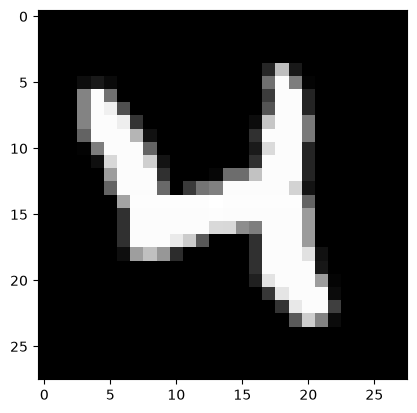

In [5]:

print(y_train[20])
plt.imshow(x_train[20],cmap = plt.cm.gray)

1
10000 10000 60000 60000
[array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0, 166, 222,  55,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0, 197, 254, 218,   5,   0,   0,   0,   0,   0,   0,   0,
         0,   0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,  29, 249, 254, 254,   9,   0,   0,   0,   0,   0,   0,   0,
         0,   0], dtype=uint8), array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,  45, 254, 254, 174,   

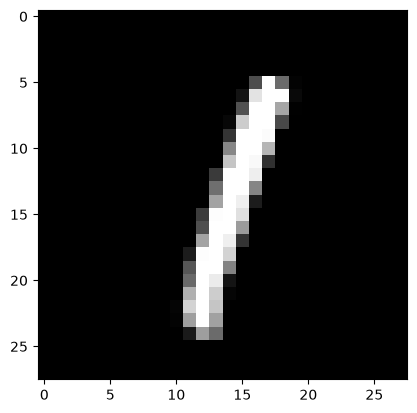

In [6]:
print(y_test[5])
plt.imshow(x_test[5],cmap = plt.cm.gray)
print(len(x_test),len(y_test),len(x_train),len(y_train))
print(x_train[24])

In [7]:
import numpy as np


for i in range(len(x_train)): 
    x_train[i] = np.array(x_train[i]) / 255
for i in range(len(x_test)):
    x_test[i] = np.array(x_test[i]) / 255



In [8]:
print(x_train[23].min())
print(x_train[23].max())
print(x_test[23].min())
print(x_test[23].max())

0.0
1.0
0.0
1.0


In [9]:
flattened_x_train = []
flattened_x_test = []
for z in range (len(x_train)):
    flattened_x_train.append((x_train[z]).reshape(-1))
for y in range(len(x_test)):
    flattened_x_test.append((x_test[y]).reshape(-1))

print(x_train[2].shape)
print(x_test[2].shape)
print(len(flattened_x_train[2]))
print(len(flattened_x_test[2]))

(28, 28)
(28, 28)
784
784


In [10]:
print(y_test[3])
new_y_train = []

for x in range(len(y_train)):
    new_y_train_sub = []
    for a in range(0,10):
        new_y_train_sub.append(0)
    #print(y_train[x])
    #print(x)
    new_y_train_sub[y_train[x]] = 1
    new_y_train.append(new_y_train_sub)


0


In [11]:
print(new_y_train)

[[0, 0, 0, 0, 0, 1, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 1, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 1, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 1, 0, 0], [0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 0, 1, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 0, 0, 0, 1, 0, 0, 0, 0, 0], [1, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 0, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 1, 0, 0], [0, 0, 0, 1, 0, 0, 0, 0, 0, 0], [0, 0, 

In [15]:
w1 = np.random.randn(784,128) * np.sqrt(2/784)
b1 = np.random.randn(1,128) 
print(w1)

[[-0.00773746 -0.04821717  0.029545   ...  0.10092811  0.07495787
   0.02063969]
 [-0.04546226  0.02864574 -0.05268248 ...  0.03706071  0.07626496
  -0.00130728]
 [-0.02797534 -0.02102929  0.0402307  ...  0.06051865  0.03135172
  -0.01735371]
 ...
 [ 0.00585717 -0.01022556  0.0386979  ...  0.00760982  0.07386801
   0.04801017]
 [ 0.08634977  0.05036625 -0.01670721 ...  0.07535707  0.03611195
  -0.03992601]
 [-0.10245695 -0.03655709 -0.0439298  ...  0.00943525  0.03228247
   0.00246265]]


In [ ]:
he initialisation + cross entropy loss 

In [16]:
w2 = np.random.randn(128,10) * np.sqrt(2/128)
b2 = np.random.randn(1,10)

print(w2.shape,b2.shape,b1.shape,w1.shape)


(128, 10) (1, 10) (1, 128) (784, 128)


In [ ]:
def ReLu(x):
    if x < 0:
        return 0
    else:
        return x

def ReLu_derivative(x):
    if x < 0:
        return 0
    else:
        return 1

def softmax(x):
    shifted_x = x -np.max(x,axis=-1,keepdims=True)
    exp_x = np.exp(shifted_x)

    sum_exp_x = np.sum(exp_x, axis = -1, keepdims=True)
    probabilities = exp_x / sum_exp_x
    
    return probabilities


In [ ]:
def move_forward(x,w1,b1,w2,b2):
    z1 = x@w1 + b1
    a1 = ReLu(z1)
    z2 = a1@w2 + b2
    a2 = softmax(z2)

    print(z1,a1,z2,a2)
    
    return a2